# Can a set model read reconstruction quality from camera layout? (results)

This notebook only **loads saved results** (CSV files, TensorBoard logs, camera tables) written by the
scripts in `bd3d-reconstruction-quality/scripts/`. It trains nothing and contains no hand-typed numbers:
every number shown is computed from those files when the notebook runs.

**Question.** Given only the aligned cameras of a photogrammetry run (where they are and where they
look), can a model predict how far the reconstructed surface is from a reference reconstruction?
The label is the v3 geometric error: symmetric RMSE between candidate and reference meshes,
normalized by the reference bounding-box diagonal, after camera-initialized similarity ICP.

In [ ]:
from pathlib import Path
import json
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

REPO = Path('..').resolve()  # repository root, relative to this notebook
R = REPO / 'results'
SYN = R / 'synthetic-coverage-gap'
PILOT = REPO / 'results/pilot-real-v3-all'
LABELS = {'arf-dog': REPO / 'results/gpu-pilot-d8-ext/labels.csv', 'pahma-5-613': REPO / 'results/pahma-5-613-v2/labels-all.csv'}
FIG = REPO / 'docs' / 'figures'
pd.set_option('display.float_format', lambda v: f'{v:.4g}')
for name, p in [('synthetic', SYN / 'summary.csv'), ('pilot', PILOT / 'summary.csv'), *LABELS.items()]:
    print(f'{name:12s} {Path(p).relative_to(REPO)}  {"found" if Path(p).exists() else "MISSING"}')

synthetic    results/synthetic-coverage-gap/summary.csv  found
pilot        results/pilot-real-v3-all/summary.csv  found
arf-dog      results/gpu-pilot-d8-ext/labels.csv  found
pahma-5-613  results/pahma-5-613-v2/labels-all.csv  found


## Setup

**Synthetic benchmark.** Sets of camera centres around an object, each in an arbitrary similarity
frame (random rotation, scale, offset), normalized by centroid and median camera distance. The target
is the largest azimuthal coverage gap. *Global*: one elevation band, gap cut from all cameras.
*Localized*: a full lower ring plus an upper ring with the gap, so the model must find which cameras
are missing. Models: training-mean floor, Ridge on rotation-invariant summaries, PointNet
(per-camera MLP + max-pool), and one self-attention layer before the max-pool. Networks are trained
with a fresh random rotation per example per step.

**Real-data pilot.** Every real run that has a v3 label and a `cameras.csv`: the ARF dog
(historical CPU runs and GPU depth-downscale-8 runs) and the PAHMA 5-613 coffin, if its runs completed.
Same networks (smaller), with view directions added to the camera positions, plus a
reprojection-RMSE baseline. Leave-one-run-out, and leave-one-artifact-out when two artifacts exist.

In [ ]:
cfg = json.loads((SYN / 'config.json').read_text())
print({k: v for k, v in cfg.items() if not isinstance(v, (dict, list)) and k not in ('out', 'runs')})

{'epochs': 400, 'eval_every': 10, 'n_train': 3000, 'n_val': 600, 'n_test': 600, 'threads': 4, 'resume': True, 'nmax': 60, 'torch': '2.15.0', 'numpy': '2.5.4', 'sklearn': '1.9.1', 'python': '3.14.7', 'wall_seconds': 726.2}


## Results
### 1. Example camera sets, largest azimuth gap shaded (reference frame)

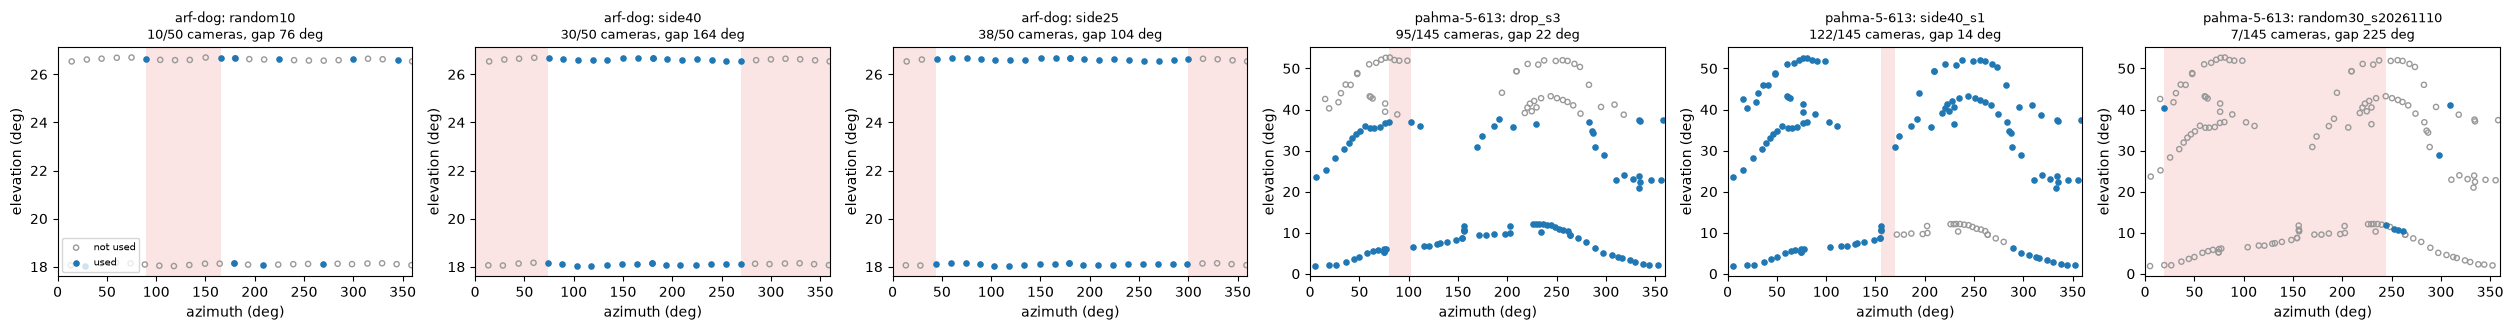

In [ ]:
def _cell():
    def frame(P, V):
        # object centre = least-squares point nearest all viewing rays; up = least-spread direction
        A = np.zeros((3, 3)); b = np.zeros(3)
        for p, v in zip(P, V):
            Q = np.eye(3) - np.outer(v, v); A += Q; b += Q @ p
        c = np.linalg.solve(A, b)
        D = P - c; D /= np.linalg.norm(D, axis=1, keepdims=True)
        up = np.linalg.eigh(np.cov(D.T))[1][:, 0]
        up = up if (D @ up).mean() > 0 else -up
        e1 = np.linalg.svd(np.eye(3) - np.outer(up, up))[0][:, 0]; e2 = np.cross(up, e1)
        return np.degrees(np.arctan2(D @ e2, D @ e1)) % 360, np.degrees(np.arcsin(np.clip(D @ up, -1, 1)))

    def cams(path):
        c = pd.read_csv(path)
        return c[c['aligned'].astype(str) == 'True'] if 'aligned' in c else c

    def largest_gap(az):
        s = np.sort(az); d = np.diff(np.r_[s, s[0] + 360]); i = d.argmax()
        return s[i], d[i]

    examples = [('arf-dog', R / 'gpu-pilot-d8/ref50', R / f'gpu-pilot-d8{sub}/{run}')
                for sub, run in [('', 'random10'), ('', 'side40'), ('-ext', 'side25')]]
    examples += [('pahma-5-613', R / 'pahma-5-613-v2/ref145b', R / f'pahma-5-613-v2/{run}')
                 for run in ['drop_s3', 'side40_s1', 'random30_s20261110']]
    examples = [e for e in examples if (e[1] / 'cameras.csv').exists() and (e[2] / 'cameras.csv').exists()]
    if not examples:  # run folders are local-only; show the exported figure instead
        from IPython.display import Image
        display(Image(filename=str(FIG / 'camera_layouts.png')))
        return
    fig, axes = plt.subplots(1, max(len(examples), 1), figsize=(4.2 * max(len(examples), 1), 3.4), squeeze=False)
    for ax, (art, ref, cand) in zip(axes[0], examples):
        rc = cams(ref / 'cameras.csv')
        az, el = frame(rc[['x', 'y', 'z']].to_numpy(), rc[['view_x', 'view_y', 'view_z']].to_numpy())
        kept = rc['label'].isin(set(cams(cand / 'cameras.csv')['label'])).to_numpy()
        start, width = largest_gap(az[kept])
        for s0 in (start, start - 360):
            ax.axvspan(s0, s0 + width, color='tab:red', alpha=0.12, lw=0)
        ax.scatter(az[~kept], el[~kept], s=14, facecolors='none', edgecolors='0.6', label='not used')
        ax.scatter(az[kept], el[kept], s=14, color='tab:blue', label='used')
        ax.set_xlim(0, 360); ax.set_xlabel('azimuth (deg)'); ax.set_ylabel('elevation (deg)')
        ax.set_title(f'{art}: {cand.name}\n{kept.sum()}/{len(kept)} cameras, gap {width:.0f} deg', fontsize=9)
    axes[0][0].legend(fontsize=7, loc='lower left')
    fig.tight_layout(); plt.show()

_cell()

### 2. Synthetic benchmark: test MAE (mean ± std over seeds)

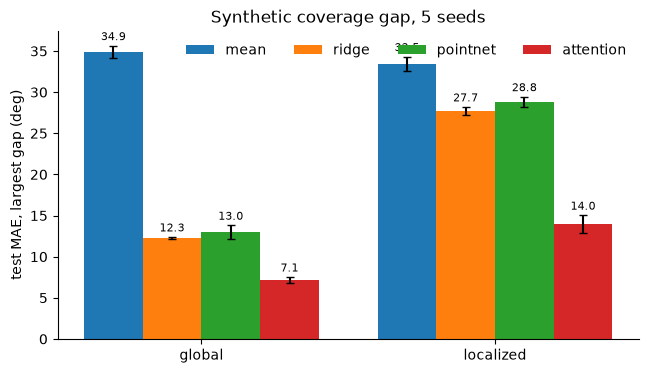

,condition,model,n_seeds,mae_mean,mae_std,skill_vs_mean,skill_std
0,global,mean,5,34.89,0.766,0,0
1,global,ridge,5,12.26,0.149,0.649,0.01
2,global,pointnet,5,12.99,0.835,0.627,0.028
3,global,attention,5,7.141,0.393,0.795,0.009
4,localized,mean,5,33.47,0.864,0,0
5,localized,ridge,5,27.7,0.513,0.172,0.009
6,localized,pointnet,5,28.82,0.631,0.139,0.014
7,localized,attention,5,13.99,1.06,0.582,0.027


In [ ]:
syn = pd.read_csv(SYN / 'summary.csv')
models = ['mean', 'ridge', 'pointnet', 'attention']
conds = list(dict.fromkeys(syn['condition']))
fig, ax = plt.subplots(figsize=(7.5, 4))
w = 0.2
for j, m in enumerate(models):
    s = syn[syn.model == m].set_index('condition').loc[conds]
    bars = ax.bar(np.arange(len(conds)) + (j - 1.5) * w, s.mae_mean, w, yerr=s.mae_std, capsize=3, label=m)
    ax.bar_label(bars, labels=[f'{v:.1f}' for v in s.mae_mean], padding=2, fontsize=8)
ax.set_xticks(range(len(conds)), conds); ax.set_ylabel('test MAE, largest gap (deg)')
ax.set_title(f'Synthetic coverage gap, {int(syn.n_seeds.iloc[0])} seeds'); ax.legend(frameon=False, ncols=4)
ax.spines[['top', 'right']].set_visible(False); plt.show()
display(syn)

### 3. Learning curves
Synthetic: validation MAE per epoch from the TensorBoard logs (mean ± std over seeds). Real pilot: training loss of the first leave-one-run-out fold.

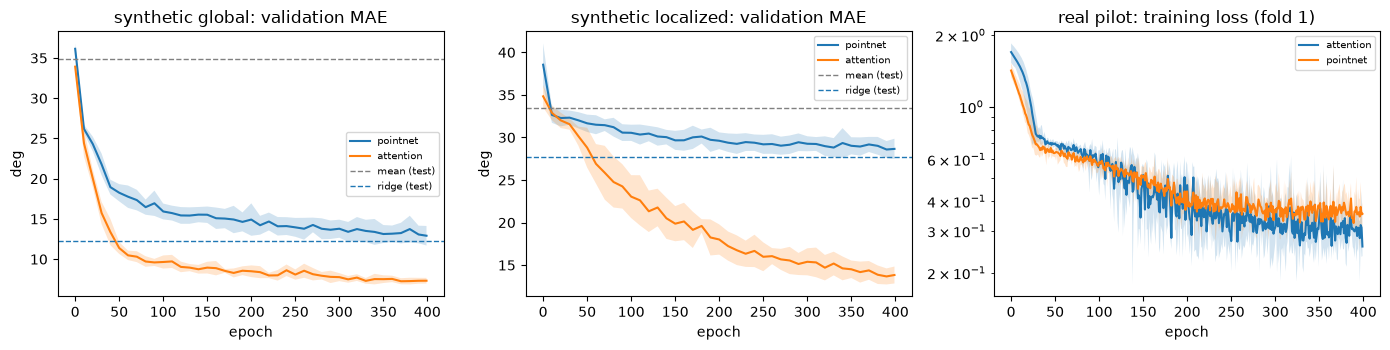

In [ ]:
def _cell():
    from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
    runs = REPO / 'runs' / 'synthetic'
    if not runs.exists():  # TensorBoard logs are not in git; show the exported figures
        from IPython.display import Image
        display(Image(filename=str(FIG / 'learning_curves_synthetic.png')), Image(filename=str(FIG / 'learning_curves_pilot.png')))
        return
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
    for ax, cond in zip(axes[:2], conds):
        for m in ['pointnet', 'attention']:
            curves = []
            for d in sorted((runs / cond / m).iterdir()):
                e = EventAccumulator(str(d)); e.Reload()
                curves.append([(s.step, s.value) for s in e.Scalars('mae_deg/val')])
            steps = np.array([s for s, _ in curves[0]]); v = np.array([[x for _, x in c] for c in curves])
            ax.plot(steps, v.mean(0), label=m); ax.fill_between(steps, v.mean(0) - v.std(0), v.mean(0) + v.std(0), alpha=0.2)
        for m in ['mean', 'ridge']:
            ax.axhline(syn[(syn.condition == cond) & (syn.model == m)].mae_mean.iloc[0], ls='--', lw=1, color='0.5' if m == 'mean' else 'tab:blue', label=f'{m} (test)')
        ax.set_title(f'synthetic {cond}: validation MAE'); ax.set_xlabel('epoch'); ax.set_ylabel('deg'); ax.legend(fontsize=7)
    lc = pd.read_csv(PILOT / 'learning_curves.csv')
    for m, g in lc.groupby('model'):
        piv = g.pivot(index='epoch', columns='seed', values='train_mse_scaled')
        axes[2].plot(piv.index, piv.mean(axis=1), label=m); axes[2].fill_between(piv.index, piv.min(axis=1), piv.max(axis=1), alpha=0.2)
    axes[2].set_yscale('log'); axes[2].set_title('real pilot: training loss (fold 1)'); axes[2].set_xlabel('epoch'); axes[2].legend(fontsize=7)
    fig.tight_layout(); plt.show()

_cell()

### 4. Real-data labels per artifact (missing vs extra surface)
*Missing* = reference surface the candidate does not reconstruct (reference→candidate); *extra* = candidate surface with no reference counterpart (candidate→reference).

In [ ]:
cols = ['run', 'images', 'label_v3', 'qc_v3', 'scale_check', 'missing_surface_rmse_norm',
        'extra_surface_rmse_norm', 'dominant_error', 'run_reprojection_rmse_px']
for art, p in LABELS.items():
    display(Markdown(f'**{art}**'))
    display(pd.read_csv(p)[cols].sort_values('label_v3') if p.exists() else Markdown('_no labels file_'))

**arf-dog**

,run,images,label_v3,qc_v3,scale_check,missing_surface_rmse_norm,extra_surface_rmse_norm,dominant_error,run_reprojection_rmse_px
5,random20_s20261111,20,0.006211,pass,agree,0.007254,0.004954,missing,0.3638
4,random20_s20261110,20,0.007162,pass,agree,0.009147,0.004351,missing,0.3371
6,side25,38,0.007779,pass,agree,0.007264,0.008262,extra,0.4529
1,side40,30,0.008491,pass,agree,0.01012,0.006462,missing,0.4325
2,random15_s20261110,15,0.008512,pass,agree,0.01049,0.005903,missing,0.3246
3,random15_s20261111,15,0.009122,pass,agree,0.01191,0.004961,missing,0.3293
0,random10,10,0.02252,pass,agree,0.03044,0.009372,missing,0.2452


**pahma-5-613**

,run,images,label_v3,qc_v3,scale_check,missing_surface_rmse_norm,extra_surface_rmse_norm,dominant_error,run_reprojection_rmse_px
3,side40_s1,122,0.008014,pass,agree,0.01123,0.001495,missing,1.161
1,drop_s2,107,0.01022,pass,agree,0.008016,0.01202,extra,0.9786
0,drop_s3,95,0.01059,pass,agree,0.01392,0.005525,missing,0.9006
4,random60_s20261112,60,0.01822,pass,agree,0.02568,0.002158,missing,0.9325
2,random30_s20261111,29,0.03539,pass,agree,0.04989,0.00386,missing,0.6661


### 5. Real-data PILOT model comparison (tiny n)

**PILOT - tiny n, not evidence of model skill.** 28 runs, artifacts: arf-dog, pahma-5-613; seeds 5; 400 epochs; hidden 32.

,scheme,model,n_runs,n_seeds,mae_mean,mae_std,skill_vs_mean,skill_std
0,LORO,mean,28,1,0.004612,0,0,0
1,LORO,reproj,28,1,0.004224,0,0.08415,0
2,LORO,ridge,28,1,0.003025,0,0.344,0
3,LORO,pointnet,28,5,0.003652,2.933e-05,0.2081,0.00636
4,LORO,attention,28,5,0.003434,0.0001327,0.2555,0.02877
5,LOAO,mean,28,1,0.01082,0,0,0
6,LOAO,reproj,28,1,0.03945,0,-2.645,0
7,LOAO,ridge,28,1,0.02365,0,-1.186,0
8,LOAO,pointnet,28,5,0.004088,0.0004445,0.6223,0.04107
9,LOAO,attention,28,5,0.003508,0.0005317,0.6759,0.04913


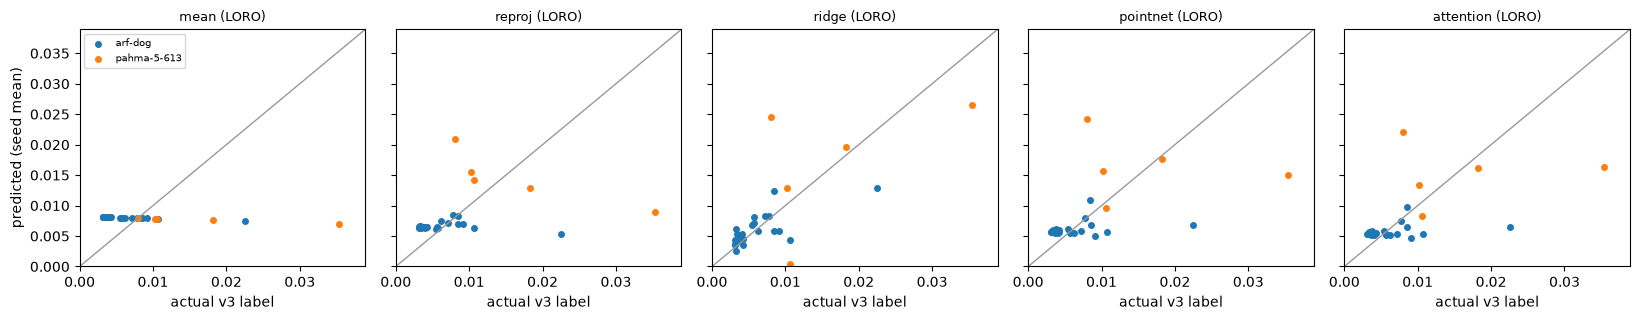

In [ ]:
cfg = json.loads((PILOT / 'config.json').read_text())
display(Markdown(f"**{cfg['status']}.** {cfg['n_runs']} runs, artifacts: {', '.join(cfg['artifacts'])}; "
                 f"seeds {len(cfg['seeds'])}; {cfg['epochs']} epochs; hidden {cfg['hidden']}."))
ps = pd.read_csv(PILOT / 'summary.csv')
display(ps)
pred = pd.read_csv(PILOT / 'predictions.csv')
loro = pred[pred.scheme == 'LORO'].groupby(['model', 'run', 'artifact'], as_index=False)[['actual', 'predicted']].mean()
show = ['mean', 'reproj', 'ridge', 'pointnet', 'attention']
fig, axes = plt.subplots(1, len(show), figsize=(3.3 * len(show), 3.3), sharex=True, sharey=True)
lim = [0, max(loro.actual.max(), loro.predicted.max()) * 1.1]
for ax, m in zip(axes, show):
    for art, g in loro[loro.model == m].groupby('artifact'):
        ax.scatter(g.actual, g.predicted, s=16, label=art)
    ax.plot(lim, lim, color='0.6', lw=1); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(f'{m} (LORO)', fontsize=9); ax.set_xlabel('actual v3 label')
axes[0].set_ylabel('predicted (seed mean)'); axes[0].legend(fontsize=7)
fig.tight_layout(); plt.show()

In [ ]:
best = ps[ps.scheme == 'LORO'].sort_values('mae_mean').iloc[0]
display(Markdown(f"Lowest LORO MAE: **{best.model}** ({best.mae_mean:.4g} ± {best.mae_std:.4g}, "
                 f"skill vs mean {best.skill_vs_mean:+.2f} ± {best.skill_std:.2f}) over {int(best.n_runs)} runs. "
                 "With this n, differences of this size are not reliable."))

Lowest LORO MAE: **ridge** (0.003025 ± 0, skill vs mean +0.34 ± 0.00) over 28 runs. With this n, differences of this size are not reliable.

## Limitations

- **Tiny n.** The real-data comparison uses a few dozen runs from at most two objects. It checks that
  the pipeline works end to end; it is not evidence that any model predicts quality.
- **Labels are reference-relative.** Each artifact (and the historical CPU vs GPU dog runs) is scored
  against its own reference reconstruction, not ground truth; pooled labels are only roughly comparable.
- **Correlated runs.** Subsets of the same capture share images, so leave-one-run-out is optimistic;
  leave-one-artifact-out is the honest test and has only two folds.
- **Designed failures.** Most candidates were built by removing images on purpose (random subsets,
  removed sides or series), so the label range reflects the experimental design, not natural captures.
- **Synthetic target differs.** The synthetic benchmark predicts a coverage gap in degrees, a proxy;
  it shows the models can read camera layout, not that layout determines surface error.